In [1]:
import math
import random
import pandas as pd

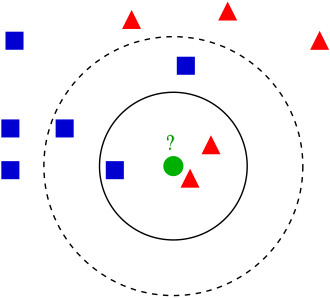

   ### Dataset


In [2]:
dataset = pd.read_csv("iris.csv")
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
# Get unique classes
classes = list(set(dataset['class'])) 
print('classes:',classes)

number_of_class = len(classes)

# Encode the 'Name' into numeric 
dataset = dataset.replace('Iris-setosa',0)
dataset = dataset.replace('Iris-versicolor',1)
dataset = dataset.replace('Iris-virginica',2)

print('\nnumber_of_records:',len(dataset))

classes: ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

number_of_records: 150


### Training and test dataset


In [4]:
# Getting random indexes
indexes = random.sample(range(0, 150), 150)

training_dataset = []
testing_dataset = []

# Splting into training and testing
for i in range(100):
    training_dataset.append(dataset.iloc[indexes[i]])
    
for i in range(100,150):
    testing_dataset.append(dataset.iloc[indexes[i]])

### The Euclidean distance function in KNN
 This function implements the KNN algorithm to classify a test example based on the k nearest examples in the training dataset.

In [5]:
def knn(training_dataset, test, k):
    
    # Euclidean Distance
    
    # ED = list(np.sqrt(np.sum(np.square(training_dataset[:,0:-1] - test[0:-1]), axis = 1)))
    ED = []
    for i in range(len(training_dataset)):
        
        add = 0.0
        for j in range(4):
            add +=((training_dataset[i][j]-test[j])**2 )
            
        ED.append(math.sqrt(add))
    
    sorted_ED = sorted(ED)
    
    KNN = []
    for i in range(k):
        index = ED.index(sorted_ED[i])
        KNN.append(training_dataset[index][-1])
    return KNN

### The KNN function call

In [6]:

k = 5

# Creating the result DataFrame
result = pd.DataFrame(columns=[
    'sepal_length',
    'sepal_width',
    'petal_length',
    'petal_width',
    'predicted_class',
    'actual_class',
    'neighbours(K)',
    'Iris-setosa',
    'Iris-versicolor',
    'Iris-virginica'
])

for i in range(len(testing_dataset)):

    KNN = knn(training_dataset, testing_dataset[i], k)

    # Counters
    setosa = 0
    versicolor = 0
    virginica = 0

    # Count neighbors belonging to each class
    for element in KNN:

        if element == 0:
            setosa += 1

        elif element == 1:
            versicolor += 1

        elif element == 2:
            virginica += 1

    # Majority vote
    unique_counts = [setosa, versicolor, virginica]
    unique_values = [
        'Iris-setosa',
        'Iris-versicolor',
        'Iris-virginica'
    ]

    predicted = unique_values[unique_counts.index(max(unique_counts))]

    # Store results
    result.loc[i] = [
        testing_dataset[i][0],  # sepal_length
        testing_dataset[i][1],  # sepal_width
        testing_dataset[i][2],  # petal_length
        testing_dataset[i][3],  # petal_width
        predicted,              # predicted_class
        unique_values[int(testing_dataset[i][4])], # actual_class
        k,                      # neighbours(K)
        setosa,
        versicolor,
        virginica
    ]


In [7]:
result

,sepal_length,sepal_width,petal_length,petal_width,predicted_class,actual_class,neighbours(K),Iris-setosa,Iris-versicolor,Iris-virginica
0,6.2,3.4,5.4,2.3,Iris-virginica,Iris-virginica,5,0,0,5
1,6.4,2.8,5.6,2.1,Iris-virginica,Iris-virginica,5,0,0,5
2,5.8,2.7,5.1,1.9,Iris-virginica,Iris-virginica,5,0,1,4
3,7.2,3.0,5.8,1.6,Iris-virginica,Iris-virginica,5,0,0,5
4,4.9,2.4,3.3,1.0,Iris-versicolor,Iris-versicolor,5,0,5,0
5,6.2,2.2,4.5,1.5,Iris-virginica,Iris-versicolor,5,0,2,3
6,4.8,3.4,1.9,0.2,Iris-setosa,Iris-setosa,5,5,0,0
7,6.4,2.7,5.3,1.9,Iris-virginica,Iris-virginica,5,0,0,5
8,5.4,3.0,4.5,1.5,Iris-versicolor,Iris-versicolor,5,0,5,0
9,5.6,2.5,3.9,1.1,Iris-versicolor,Iris-versicolor,5,0,5,0


## Model evaluation
### Accuracy, Precision, Recall, F1-score


In [8]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
y_true = result['actual_class']
y_pred = result['predicted_class']

Confusion Matrix:
[[15  0  0]
 [ 0 15  2]
 [ 0  2 16]]


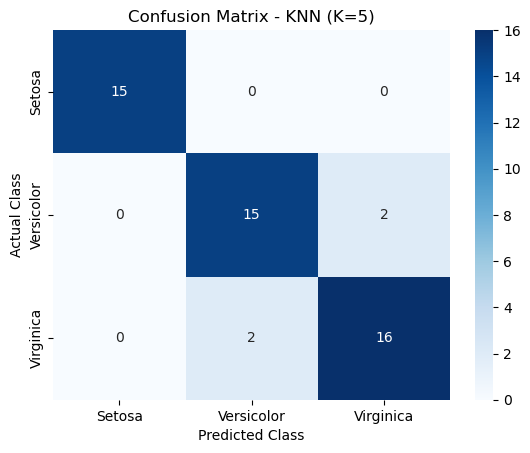

In [10]:
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Setosa', 'Versicolor', 'Virginica'],
            yticklabels=['Setosa', 'Versicolor', 'Virginica'])

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Confusion Matrix - KNN (K=5)')
plt.show()

In [11]:
# Accuracy
accuracy = accuracy_score(y_true, y_pred)

# Precision
precision = precision_score(y_true, y_pred, average='macro')

# Recall
recall = recall_score(y_true, y_pred, average='macro')

# F1-score
f1 = f1_score(y_true, y_pred, average='macro')

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)

Accuracy : 0.92
Precision: 0.9237472766884531
Recall   : 0.9237472766884531
F1-score : 0.9237472766884531


## Predicting a new flower's class

 sepal_length=5.1,  	sepal_width=3.5,  	petal_length=1.4,	petal_width=0.2

In [16]:
# New flower
new_data = [5.1, 5, 1.4, 7]

# Number of neighbors
k = 33

# Apply KNN
KNN = knn(training_dataset, new_data, k)

print("Neighbors classes:", KNN)

setosa = 0
versicolor = 0
virginica = 0

for element in KNN:
    if element == 0:
        setosa += 1
    elif element == 1:
        versicolor += 1
    elif element == 2:
        virginica += 1

counts = [setosa, versicolor, virginica]

classes = [
    'Iris-setosa',
    'Iris-versicolor',
    'Iris-virginica'
]

predicted_class = classes[counts.index(max(counts))]

print("Setosa neighbors:", setosa)
print("Versicolor neighbors:", versicolor)
print("Virginica neighbors:", virginica)

print("\nPredicted class:", predicted_class)

Neighbors classes: [1.0, 1.0, 2.0, 2.0, 1.0, 1.0, 2.0, 1.0, 2.0, 0.0, 2.0, 1.0, 2.0, 0.0, 2.0, 1.0, 1.0, 0.0, 0.0, 2.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0, 2.0, 2.0, 1.0, 1.0, 2.0, 1.0, 2.0]
Setosa neighbors: 7
Versicolor neighbors: 14
Virginica neighbors: 12

Predicted class: Iris-versicolor
